# Лабораторная работа 2: Классификация. Нейронные сети

---

## Цель работы
Изучение методов классификации данных, реализованные в библиотеке Scikit-Learn, а также ознакомление с нейронными сетями с использованием библиотек TensorFlow и TensorBoard. 


## Постановка задачи

1. Необходимо выбрать и подготовить датасет для классификации, затем построить классификационные модели с помощью пяти методов:
    
    а. Наивный Байесовский классификатор (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB),

    б. Деревья решений (Decision Tree),

    в. Линейный дискриминантный анализ (Linear Discriminant Analysis),

    г. Метод опорных векторов (Support Vector Machines),

    д. Метод ближайших соседей (k-Nearest Neighbors),

2. Затем сравните качество работы классификаторов с помощью следующих метрик:

    а. Accuracy (точность),

    б. Precision (доля правильно классифицированных положительных примеров),

    в. Recall (чувствительность, доля верно найденных положительных примеров),

    г. F1-Score (среднее гармоническое precision и recall),

    д. Площадь под кривой ROC (AUC-ROC).

3. Настройте гиперпараметры каждого метода и проведите исследование влияния различных параметров на качество классификации.

4. Реализуйте и протестируйте нейронную сеть на TensorFlow, исследуйте эффект настройки гиперпараметров и визуализируйте процесс обучения с помощью инструмента TensorBoard.

## Описание датасета

Iris dataset - Классификации цветков ириса
(https://www.kaggle.com/datasets/himanshunakrani/iris-dataset)

Датасет включает 4 факторов и 1 целевую переменную.

Свойства:
1. Длина чашелистика (SepalLengthCm) — длина чашелистика в сантиметрах.
2. Ширина чашелистика (SepalWidthCm) — ширина чашелистика в сантиметрах.
3. Длина лепестка (PetalLengthCm) — длина лепестка в сантиметрах.
4. Ширина лепестка (PetalWidthCm) — ширина лепестка в сантиметрах.

Целевая переменная:  
5. Вид ириса (Species или Variety) — категориальная переменная, определяющая вид цветка.

В датасете представлены три класса ирисов:

- Iris setosa;

- Iris versicolor;

- Iris virginica.

Стандартный набор данных содержит 150 наблюдений, по 50 объектов каждого класса.


In [5]:
import os
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import tensorflow as tf

from sklearn.preprocessing import (
    LabelEncoder, StandardScaler, MinMaxScaler, label_binarize
)
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc, classification_report
)

from sklearn.naive_bayes import (
    GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

SEED = 67
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

path = kagglehub.dataset_download("himanshunakrani/iris-dataset")
csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("В скачанном датасете не найден CSV-файл.")

df = pd.read_csv(os.path.join(path, csv_files[0]))
df.columns = df.columns.str.strip()

print("Размерность датасета:", df.shape)
print("Первая строка датасета:")
print(df.head(1).to_string())
print("\nТипы столбцов:")
print(df.dtypes)

target_candidates = [
    c for c in df.columns
    if c.lower() in ["variety", "species", "class", "target"]
]

if not target_candidates:
    raise ValueError(
        "Не найден столбец класса. Проверьте названия столбцов: "
        + str(df.columns.tolist())
    )

target_col = target_candidates[0]

df = df.dropna(subset=[target_col]).copy()

id_cols = [
    c for c in df.columns
    if c.lower() in ["id", "unnamed: 0"]
]
df = df.drop(columns=id_cols, errors="ignore")

X = df.drop(columns=[target_col]).copy()
y = df[target_col].copy()

X = X.apply(pd.to_numeric, errors="coerce")

X = X.fillna(X.median(numeric_only=True))

if X.isnull().any().any():
    raise ValueError("После обработки остались пропуски в признаках.")

le = LabelEncoder()
y = le.fit_transform(y)

n_classes = len(le.classes_)
if n_classes < 2:
    raise ValueError("Для классификации необходимо минимум два класса.")

print("\nКлассы:", le.classes_)
print("Количество объектов:", len(X))
print("Количество признаков:", X.shape[1])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

scaler_std = StandardScaler()
X_train_std = scaler_std.fit_transform(X_train)
X_test_std = scaler_std.transform(X_test)

scaler_minmax = MinMaxScaler()
X_train_mm = scaler_minmax.fit_transform(X_train)
X_test_mm = scaler_minmax.transform(X_test)

Размерность датасета: (150, 5)
Первая строка датасета:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa

Типы столбцов:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object

Классы: ['setosa' 'versicolor' 'virginica']
Количество объектов: 150
Количество признаков: 4


В предварительной подготовке было посчитана размерность, продемонстрированна строка пример, приведенны типы столбцов, сформированны признаки и целевая переменная. Также произведенно кодирование целевой пеерменной (0 - setosa, 1 - versicolor, 2 - virginica).

В программе выборка раздделена на обучающую и тестовую в отношении 70:30. Для масштабирования признаков были применены стандартизация и нормализация методом Min-Max.

Информация про отстуствие пустых строк была известна при выборе датасета, поэтому в дополнительном анализе не нуждается.

# Наивный Байесовский классификатор

Вероятностный метод, основанный на теореме Байеса. Он определяет принадлежность объекта к определённому классу, вычисляя вероятность этого класса при заданных значениях признаков. Основное предположение метода заключается в том, что все признаки условно независимы друг от друга при известном классе объекта. Это предположение упрощает вычисления и позволяет эффективно применять алгоритм даже на относительно небольших наборах данных.

При классификации алгоритм оценивает вероятность каждого возможного класса и выбирает класс с наибольшей апостериорной вероятностью. В библиотеке scikit-learn реализовано несколько разновидностей наивного байесовского классификатора, отличающихся предположениями о распределении признаков и типе входных данных.

1. GaussianNB — гауссовский наивный Байес
Применяется в задачах, где признаки представлены непрерывными числовыми значениями. Алгоритм предполагает, что значения каждого признака внутри каждого класса распределены по нормальному (гауссовскому) закону. В процессе обучения оцениваются среднее значение и дисперсия каждого признака для каждого класса, после чего вычисляются вероятности принадлежности объектов к классам.

GaussianNB использует стандартизированные данные, подготовленные с помощью StandardScaler.

2. MultinomialNB — мультиномиальный наивный Байес
Предназначен преимущественно для дискретных неотрицательных признаков, например частот слов в текстах или количества появлений определённых событий. Алгоритм оценивает вероятности значений признаков для каждого класса и использует их при вычислении итоговой вероятности классификации.

MultinomialNB получает данные, преобразованные с помощью MinMaxScaler, что позволяет привести числовые признаки к неотрицательному диапазону.

3. ComplementNB — комплементарный наивный Байес
Разновидность мультиномиального наивного байесовского классификатора, разработанная для улучшения работы с несбалансированными классами. При оценке параметров алгоритм учитывает статистику признаков для объектов, не принадлежащих рассматриваемому классу, то есть использует информацию о его дополнении. Такой подход часто повышает устойчивость классификации текстовых данных, особенно при неравномерном распределении классов.

ComplementNB, как и MultinomialNB, использует признаки, преобразованные методом MinMaxScaler. Это обеспечивает неотрицательность значений, необходимую для стандартного применения алгоритма.

4. BernoulliNB — бернуллиевский наивный Байес
Предназначен для признаков, принимающих два значения, обычно 0 и 1. Алгоритм моделирует наличие или отсутствие признака и оценивает вероятность каждого такого события для соответствующего класса. Он широко применяется в задачах обработки текста, например при классификации документов по факту присутствия определённых слов.

BernoulliNB использует стандартизированные признаки.

# Деревья решений

Алгоритм, который используется для решения задач классификации и регрессии. Его принцип работы в последовательном разделении объектов на группы на основе значений признаков. Структура модели представлена в виде дерева, состоящего из корневого узла, внутренних узлов и листьев. Корневой узел содержит весь набор обучающих данных, внутренние узлы соответствуют условиям разделения по признакам, а листья определяют итоговый класс объекта.

# Линейный дискриминантный анализ

Основная цель метода заключается в нахождении линейных комбинаций признаков, которые позволяют максимально эффективно разделять объекты разных классов. Алгоритм учитывает различия между средними значениями классов и разбросом данных внутри каждого класса, стремясь увеличить расстояние между классами и уменьшить внутриклассовую дисперсию.

В основе лежит предположение, что признаки внутри каждого класса имеют многомерное нормальное распределение, а ковариационные матрицы классов одинаковы. При выполнении этих условий алгоритм строит линейные границы принятия решений, по которым новые объекты относятся к одному из известных классов.

# Метод опорных векторов

Основная идея метода - поиск оптимальной разделяющей границы между классами, которая обеспечивает максимально возможное расстояние до ближайших объектов каждого класса. Такие объекты называются опорными векторами, поскольку именно они определяют положение разделяющей границы. Одним из преимуществ SVM является возможность построения как линейных, так и нелинейных границ классификации.

# Метод ближайших соседей

Логика метода в том, что объекты с похожими характеристиками, как правило, принадлежат к одному классу. Для классификации нового объекта алгоритм находит \(K\) ближайших к нему объектов из обучающей выборки и определяет класс на основе голосования среди найденных соседей.

Расстояние между объектами вычисляется с помощью выбранной метрики. Класс нового объекта обычно определяется большинством голосов среди ближайших соседей, хотя возможны и варианты с учётом расстояния до каждого соседа.

In [ ]:
models = {
    "GaussianNB": (GaussianNB(), "std"),
    "MultinomialNB": (MultinomialNB(), "mm"),
    "ComplementNB": (ComplementNB(), "mm"),
    "BernoulliNB": (BernoulliNB(), "std"),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED), "std"
    ),
    "LDA": (LinearDiscriminantAnalysis(), "std"),
    "SVM": (
    CalibratedClassifierCV(
        estimator=SVC(random_state=SEED),
        cv=5
    ),
    "std"
),
    "KNN": (KNeighborsClassifier(), "std")
}

X_data = {
    "std": (X_train_std, X_test_std),
    "mm": (X_train_mm, X_test_mm)
}

y_test_bin = label_binarize(
    y_test, classes=np.arange(n_classes)
)

results = []
trained_models = {}
roc_scores = {}

Для проведения экспериментов был сформирован набор моделей классификации, включающий Gaussian Naive Bayes, Multinomial Naive Bayes, Complement Naive Bayes, Bernoulli Naive Bayes, дерево решений (Decision Tree), линейный дискриминантный анализ (LDA), метод опорных векторов (SVM) и метод ближайших соседей (KNN).

Для разных алгоритмов предусмотрено использование стандартизированных признаков или признаков, нормализованных методом Min-Max.

Дополнительно подготовлены структуры для хранения обученных моделей и результатов экспериментов, а также выполнено бинарное кодирование целевой переменной для последующего ROC-анализа при многоклассовой классификации.

In [11]:
from sklearn.calibration import CalibratedClassifierCV

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

search_configs = {
    "GaussianNB": (
        GaussianNB(),
        StandardScaler(),
        {"model__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5]}
    ),
    "MultinomialNB": (
        MultinomialNB(),
        MinMaxScaler(),
        {"model__alpha": [0.01, 0.1, 0.5, 1.0, 2.0]}
    ),
    "ComplementNB": (
        ComplementNB(),
        MinMaxScaler(),
        {"model__alpha": [0.01, 0.1, 0.5, 1.0, 2.0]}
    ),
    "BernoulliNB": (
        BernoulliNB(),
        StandardScaler(),
        {
            "model__alpha": [0.1, 0.5, 1.0, 2.0],
            "model__binarize": [0.0, 0.5, 1.0]
        }
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        StandardScaler(),
        {
            "model__max_depth": [2, 3, 4, 5, None],
            "model__min_samples_split": [2, 5, 10],
            "model__criterion": ["gini", "entropy"]
        }
    ),
    "LDA": (
        LinearDiscriminantAnalysis(),
        StandardScaler(),
        {
            "model__solver": ["svd", "lsqr"],
            "model__shrinkage": [None, "auto"]
        }
    ),
    "SVM": (
    SVC(random_state=SEED),
    StandardScaler(),
    {
        "model__C": [0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    }
    ),
    "KNN": (
        KNeighborsClassifier(),
        StandardScaler(),
        {
            "model__n_neighbors": [1, 3, 5, 7, 9, 11],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    )
}

tuning_results = []
best_models = {}

for name, (estimator, scaler, param_grid) in search_configs.items():
    pipe = Pipeline([
        ("scaler", scaler),
        ("model", estimator)
    ])

    if name == "LDA":
        param_grid = [
            {
                "model__solver": ["svd"]
            },
            {
                "model__solver": ["lsqr"],
                "model__shrinkage": [None, "auto"]
            }
        ]

    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_

    y_pred = search.predict(X_test)

    tuning_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Best Parameters": str(search.best_params_)
    })

    print(f"\n{name}")
    print("Лучшие параметры:", search.best_params_)
    print("Лучший CV F1:", round(search.best_score_, 4))

tuning_df = pd.DataFrame(tuning_results)
print("\nРЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ")
print(tuning_df.round(4).to_string(index=False))
tuning_df.to_csv("hyperparameter_results.csv", index=False)



GaussianNB
Лучшие параметры: {'model__var_smoothing': 1e-11}
Лучший CV F1: 0.9521

MultinomialNB
Лучшие параметры: {'model__alpha': 0.01}
Лучший CV F1: 0.7899

ComplementNB
Лучшие параметры: {'model__alpha': 0.01}
Лучший CV F1: 0.5556

BernoulliNB
Лучшие параметры: {'model__alpha': 0.1, 'model__binarize': 0.5}
Лучший CV F1: 0.8559

Decision Tree
Лучшие параметры: {'model__criterion': 'gini', 'model__max_depth': 4, 'model__min_samples_split': 2}
Лучший CV F1: 0.9518

LDA
Лучшие параметры: {'model__solver': 'svd'}
Лучший CV F1: 0.9904

SVM
Лучшие параметры: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Лучший CV F1: 0.9714

KNN
Лучшие параметры: {'model__n_neighbors': 9, 'model__p': 2, 'model__weights': 'uniform'}
Лучший CV F1: 0.9713

РЕЗУЛЬТАТЫ ПОДБОРА ГИПЕРПАРАМЕТРОВ
        Model  Best CV F1  Test Accuracy  Test F1                                                                    Best Parameters
   GaussianNB      0.9521         0.9111   0.9111                   

Для автоматического подбора параметров использовался метод GridSearchCV с пятикратной стратифицированной кросс-валидацией. В качестве основной метрики оптимизации был выбран F1-macro, который рассчитывает среднее значение F1-меры по всем классам, придавая каждому классу одинаковый вес. Для каждой модели проверялись различные комбинации гиперпараметров, после чего выбиралась конфигурация с наилучшим средним результатом кросс-валидации.

Исследуемые гиперпараметры
- Gaussian Naive Bayes: исследовалось влияние параметра var_smoothing, регулирующего добавление небольшой величины к дисперсиям признаков для повышения численной устойчивости модели.

- Multinomial Naive Bayes: изменялся параметр alpha, отвечающий за сглаживание вероятностей. Для этой модели использовался MinMaxScaler, позволяющий привести признаки к неотрицательному диапазону.

- Complement Naive Bayes: проверялись различные значения alpha, чтобы определить влияние сглаживания на качество классификации.

- Bernoulli Naive Bayes: исследовалось влияние параметров alpha и binarize. Первый регулирует сглаживание вероятностей, второй задаёт порог преобразования числовых признаков в бинарные значения.

- Decision Tree: изменялись максимальная глубина дерева (max_depth), минимальное количество объектов для разделения узла (min_samples_split) и критерий разделения (criterion: gini или entropy). Эти эксперименты позволяли оценить влияние сложности дерева на качество классификации.

- Linear Discriminant Analysis (LDA): сравнивались алгоритмы вычисления дискриминантных функций (solver) и варианты регуляризации ковариационной матрицы (shrinkage). Для solver='svd' регуляризация не применялась, поскольку данный алгоритм не поддерживает параметр shrinkage.

- Support Vector Machine (SVM): изменялись параметр регуляризации C, тип ядра kernel и параметр gamma. Рассматривались линейное и радиально-базисное (RBF) ядра, что позволяло сравнить разные способы построения границ между классами.

- K-Nearest Neighbors (KNN): исследовалось влияние количества ближайших соседей (n_neighbors), способа взвешивания соседей (weights) и метрики расстояния (p). Проверялись варианты с равными весами соседей и с учётом расстояния, а также манхэттенское и евклидово расстояния.

После выбора оптимальных гиперпараметров каждая модель оценивалась на тестовой выборке, которая не использовалась при подборе параметров. Для сравнения рассчитывались метрики Accuracy и F1-macro. Дополнительно сохранялись лучшие параметры и средний результат кросс-валидации.

По полученным результатам среди представленных моделей наилучшие показатели продемонстрировал LDA.

In [ ]:
X_nn_train, X_val, y_nn_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train
)

nn_scaler = StandardScaler()
X_nn_train = nn_scaler.fit_transform(X_nn_train)
X_val = nn_scaler.transform(X_val)
X_nn_test = nn_scaler.transform(X_test)

y_nn_train_cat = tf.keras.utils.to_categorical(
    y_nn_train, num_classes=n_classes
)
y_val_cat = tf.keras.utils.to_categorical(
    y_val, num_classes=n_classes
)
y_test_cat = tf.keras.utils.to_categorical(
    y_test, num_classes=n_classes
)

def create_nn(units=16, dropout_rate=0.2, learning_rate=0.001):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_nn_train.shape[1],)),
        tf.keras.layers.Dense(units, activation="relu"),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(max(units // 2, 4), activation="relu"),
        tf.keras.layers.Dense(n_classes, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

log_root = os.path.join(os.getcwd(), "logs", "fit")
os.makedirs(log_root, exist_ok=True)

nn_configs = [
    {"units": 16, "dropout_rate": 0.2, "learning_rate": 0.001},
    {"units": 32, "dropout_rate": 0.2, "learning_rate": 0.001},
    {"units": 32, "dropout_rate": 0.4, "learning_rate": 0.001},
    {"units": 32, "dropout_rate": 0.2, "learning_rate": 0.01}
]

nn_results = []
nn_histories = []
nn_models = []

for i, config in enumerate(nn_configs, start=1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    nn = create_nn(**config)
    run_name = (
        f"run_{i}_units{config['units']}"
        f"_dropout{config['dropout_rate']}"
        f"_lr{config['learning_rate']}_"
        + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    )
    log_dir = os.path.join(log_root, run_name)

    callbacks = [
        tf.keras.callbacks.TensorBoard(
            log_dir=log_dir,
            histogram_freq=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=15,
            restore_best_weights=True
        )
    ]

    history = nn.fit(
        X_nn_train, y_nn_train_cat,
        validation_data=(X_val, y_val_cat),
        epochs=150,
        batch_size=8,
        callbacks=callbacks,
        verbose=0
    )

    test_loss, test_accuracy = nn.evaluate(
        X_nn_test, y_test_cat, verbose=0
    )
    test_pred = np.argmax(nn.predict(X_nn_test, verbose=0), axis=1)

    nn_results.append({
        **config,
        "Test Loss": test_loss,
        "Test Accuracy": test_accuracy,
        "Test F1": f1_score(
            y_test, test_pred, average="macro", zero_division=0
        ),
        "Log Directory": log_dir
    })

    nn_histories.append((config, history))
    nn_models.append(nn)

nn_results_df = pd.DataFrame(nn_results)
print("\nРЕЗУЛЬТАТЫ НЕЙРОННОЙ СЕТИ")
print(nn_results_df.round(4).to_string(index=False))
nn_results_df.to_csv("neural_network_results.csv", index=False)

Исходная обучающая выборка была разделена на обучающую и валидационную части в соотношении 80:20.

Для стандартизации признаков применялся StandardScaler. Он обучался только на обучающей части, после чего те же преобразования применялись к валидационной и тестовой выборкам. Такой подход позволяет избежать утечки информации из валидационных и тестовых данных.

Метки классов преобразовывались в категориальный формат с помощью to_categorical, что необходимо для обучения сети с несколькими выходными классами и функцией потерь categorical_crossentropy.

### Архитектура нейронной сети

Модель создаётся с помощью tf.keras.Sequential и состоит из следующих слоёв:
1. Входной слой (Input) принимает четыре числовых признака цветка Iris.
2. Первый полносвязный слой (Dense) содержит настраиваемое количество нейронов и использует функцию активации ReLU (relu).
3. Слой Dropout случайным образом отключает заданную долю нейронов во время обучения. Он используется для снижения риска переобучения.
4. Второй полносвязный слой (Dense) содержит половину числа нейронов первого слоя, но не менее четырёх. Для активации также используется ReLU.
5. Выходной слой (Dense) содержит три нейрона — по одному на каждый класс Iris. Функция активации Softmax (softmax) преобразует выходные значения в вероятности принадлежности к классам.

### Функция потерь и оптимизатор

Для обучения модели используются следующие настройки:
- Функция активации ReLU применяется в скрытых слоях и позволяет сети обучать нелинейные зависимости между признаками.
- Функция активации Softmax используется на выходном слое для получения вероятностей принадлежности объектов к каждому классу.
- Categorical Crossentropy (categorical_crossentropy) применяется в качестве функции потерь, поскольку задача предполагает многоклассовую классификацию с категориально закодированными метками.
- Оптимизатор Adam используется для обновления весов сети. Скорость обучения (learning_rate) является настраиваемым гиперпараметром.
- Accuracy используется как дополнительная метрика для оценки доли правильно классифицированных объектов в процессе обучения.

### Эксперименты с гиперпараметрами

Для оценки влияния гиперпараметров были проведены четыре эксперимента. В каждом запуске менялись количество нейронов первого скрытого слоя, коэффициент Dropout или скорость обучения.

Во всех экспериментах использовались одинаковые значения максимального количества эпох — 150 и размера батча — 8 объектов.

В ходе экспериментов исследовалось следующее:
- Количество нейронов: сравнение 16 и 32 нейронов позволяет оценить влияние размера скрытого слоя на способность модели выявлять закономерности в данных.
- Коэффициент Dropout: увеличение значения с 0.2 до 0.4 позволяет проверить, помогает ли более сильная регуляризация уменьшить переобучение.
- Скорость обучения: изменение значения с 0.001 до 0.01 позволяет оценить влияние величины шага обновления весов на скорость и стабильность обучения.

### Графики обучения и валидации

![Рисунок 1 — Изменение функции потерь и точности обучения нейронной сети с 16 нейронами в первом скрытом слое.](image/units_16.png)

Рисунок 1 — Изменение функции потерь и точности обучения нейронной сети с 16 нейронами в первом скрытом слое.

По графикам видно, что функция потерь на обучающей и валидационной выборках постепенно уменьшается. Точность на валидационной выборке достигает 100% и сохраняется на этом уровне на протяжении большей части обучения. Точность на обучающей выборке колеблется примерно в диапазоне 0.9–1.0. Это указывает на хорошее качество обучения модели.

![Рисунок 2 — Изменение функции потерь и точности обучения нейронной сети с 32 нейронами в первом скрытом слое.](image/units_32_02.png)

Рисунок 2 — Изменение функции потерь и точности обучения нейронной сети с 32 нейронами в первом скрытом слое.

При увеличении числа нейронов до 32 функция потерь уменьшается быстрее и достигает более низких значений. Точность на обучающей и валидационной выборках быстро повышается и приближается к 100%. По сравнению с первым экспериментом увеличенная размерность скрытого слоя обеспечивает более быстрое снижение функции потерь, однако итоговая точность на тестовой выборке остаётся такой же.

![Рисунок 3 — Изменение функции потерь и точности обучения при увеличении коэффициента Dropout до 0.4.](image/units_32_04.png)

Рисунок 3 — Изменение функции потерь и точности обучения при увеличении коэффициента Dropout до 0.4.

В данном эксперименте коэффициент Dropout увеличен с 0.2 до 0.4. Функция потерь продолжает уменьшаться, а точность на валидационной выборке достигает 100%. При этом более сильное отключение нейронов во время обучения не приводит к улучшению итоговых тестовых метрик. Это показывает, что увеличение интенсивности регуляризации не всегда повышает качество классификации на небольших наборах данных.

![Рисунок 4 — Изменение функции потерь и точности обучения при увеличении скорости обучения до 0.01.](image/units_32_02_001.png)

Рисунок 4 — Изменение функции потерь и точности обучения при увеличении скорости обучения до 0.01.

При увеличении скорости обучения до 0.01 модель достигает высокой точности за меньшее количество эпох. Функция потерь быстро снижается, а точность на валидационной выборке достигает 100% уже в начале обучения. При этом обучение завершается раньше, чем в предыдущих экспериментах, благодаря механизму Early Stopping. Полученные результаты демонстрируют, что увеличение скорости обучения ускоряет сходимость модели, но не обеспечивает повышения итоговой точности на тестовой выборке.

![Таблица 1 — Результаты экспериментов по настройке гиперпараметров нейронной сети.](image/table.png)

Таблица 1 — Результаты экспериментов по настройке гиперпараметров нейронной сети.

Во всех четырёх экспериментах значения Test Accuracy и Test F1 составили 0.9333. Следовательно, изменение количества нейронов, коэффициента Dropout и скорости обучения не повлияло на итоговую точность классификации тестовой выборки.

Наименьшее значение функции потерь на тестовой выборке — 0.1047 — получено во втором эксперименте с 32 нейронами, коэффициентом Dropout 0.2 и скоростью обучения 0.001. Поэтому эту конфигурацию можно считать лучшей среди проверенных по показателю Test Loss, хотя по Accuracy и F1 все конфигурации показали одинаковый результат.

In [16]:
%tensorboard --logdir logs/fit --port 6008

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6007 (pid 14556), started 0:01:54 ago. (Use '!kill 14556' to kill it.)


СРАВНЕНИЕ КЛАССИФИКАТОРОВ
        Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
          LDA    0.9556     0.9556  0.9556    0.9556   0.9956
Decision Tree    0.9333     0.9345  0.9333    0.9333   0.9500
          SVM    0.9333     0.9345  0.9333    0.9333   0.9970
   GaussianNB    0.9111     0.9111  0.9111    0.9111   0.9867
          KNN    0.8889     0.8899  0.8889    0.8888   0.9896
  BernoulliNB    0.7778     0.8219  0.7778    0.7608   0.8644
MultinomialNB    0.7556     0.7560  0.7556    0.7553   0.8319
 ComplementNB    0.6667     0.4849  0.6667    0.5499   0.8719


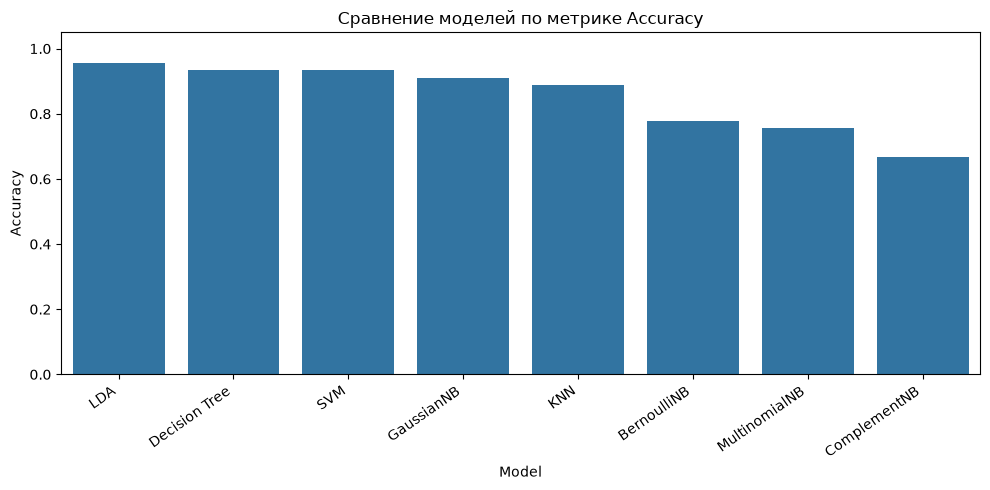

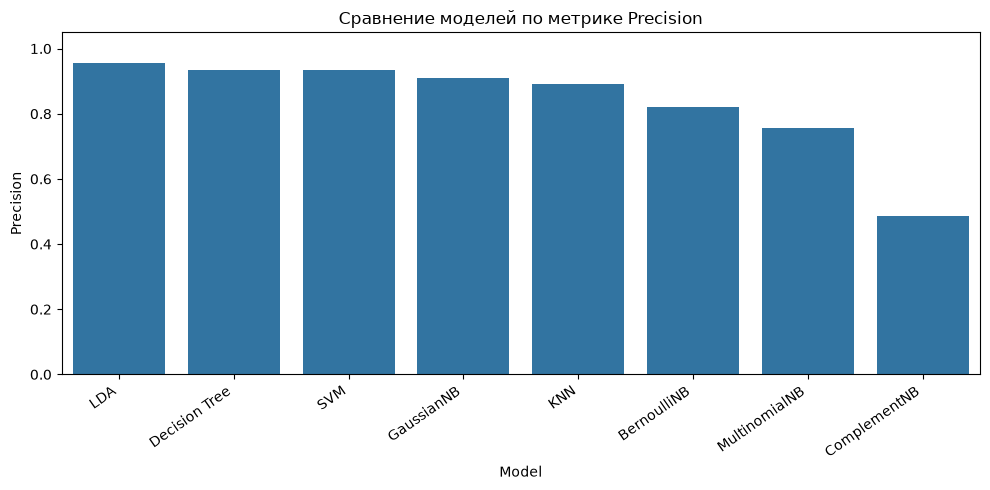

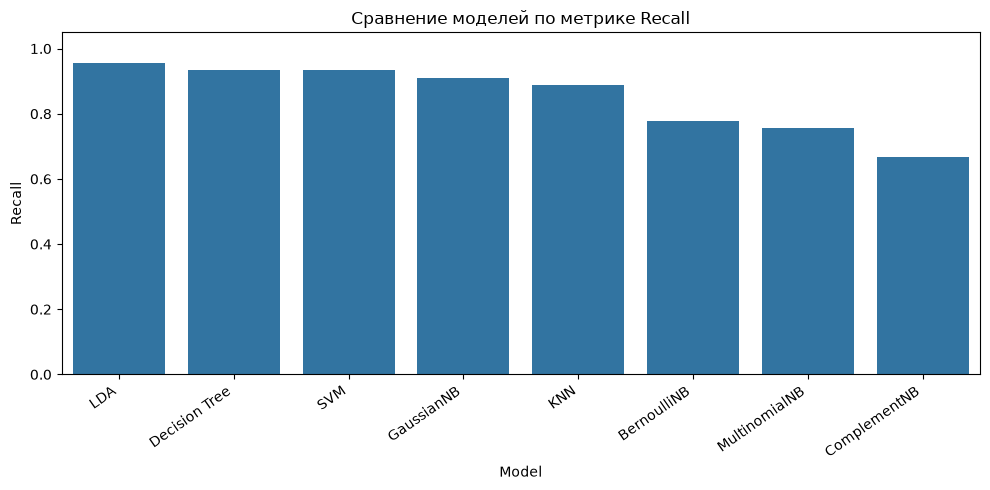

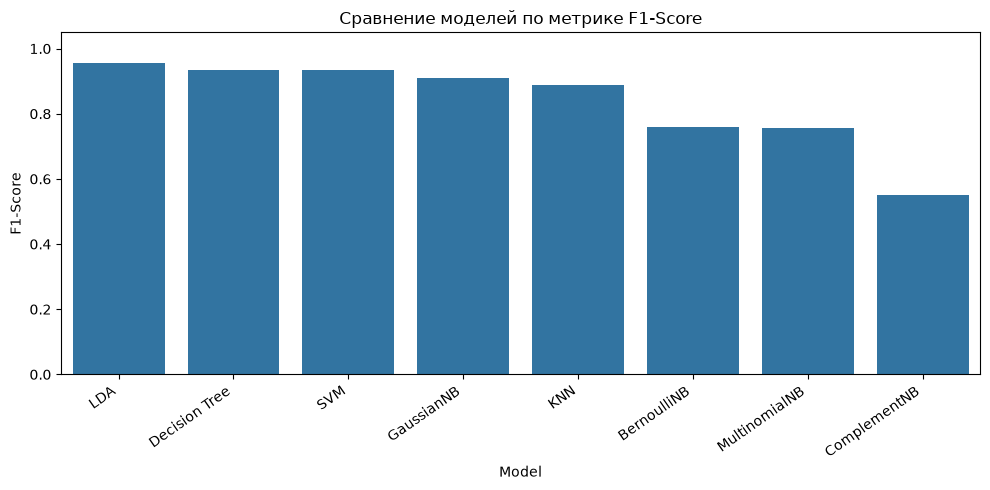

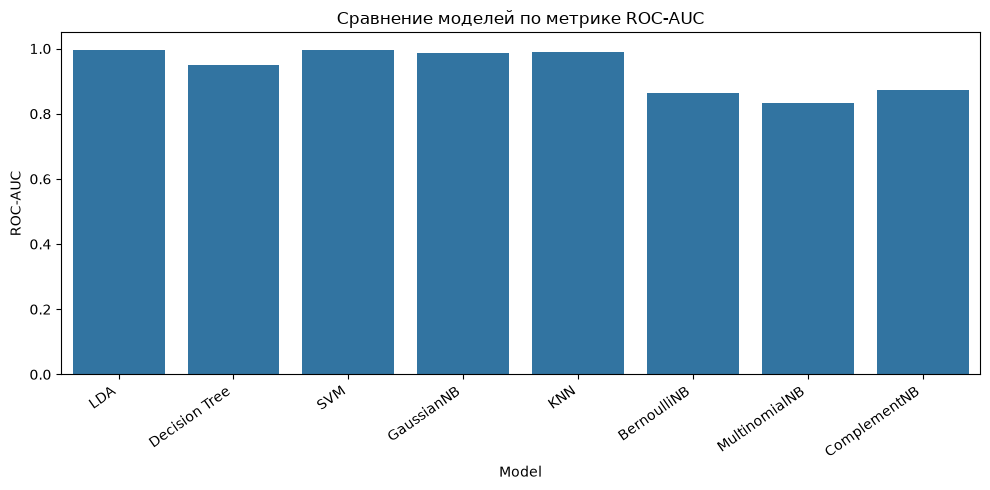

In [33]:
%matplotlib inline
print("\nСРАВНЕНИЕ КЛАССИФИКАТОРОВ")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "classification_results.csv", index=False
)

metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

for metric in metrics:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=results_df,
        x="Model", y=metric
    )
    plt.title(f"Сравнение моделей по метрике {metric}")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
    plt.close()
    
for model_name, y_score in roc_scores.items():
    plt.figure(figsize=(7, 5))

    if n_classes == 2:
        score = (
            y_score[:, 1] if y_score.ndim == 2
            else y_score
        )
        fpr, tpr, _ = roc_curve(y_test, score)
        plt.plot(
            fpr, tpr,
            label=f"AUC = {auc(fpr, tpr):.3f}"
        )
    else:
        for i, class_name in enumerate(le.classes_):
            fpr, tpr, _ = roc_curve(
                y_test_bin[:, i], y_score[:, i]
            )
            plt.plot(
                fpr, tpr,
                label=f"{class_name} (AUC={auc(fpr, tpr):.3f})"
            )

    plt.plot([0, 1], [0, 1], "k--", label="Случайный классификатор")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC-кривая: {model_name}")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

![ROC-кривая GNB](image/ROC_GNB.png)
![ROC-кривая MNB](image/ROC_MNB.png)
![ROC-кривая CNB](image/ROC_CNB.png)
![ROC-кривая BNB](image/ROC_BNB.png)
![ROC-кривая tree](image/ROC_tree.png)
![ROC-кривая LDA](image/ROC_LDA.png)
![ROC-кривая SVM](image/ROC_SVM.png)
![ROC-кривая KNN](image/ROC_KNN.png)

Лучше всего себя показал Линейный дискриминантный анализ (LDA) по совокупности метрик.

Модель LDA демонстрирует наивысшие показатели точности (Accuracy = 0.9556), полноты (Recall = 0.9556) и балансирующей метрики F1-Score (0.9556), а также удерживает превосходный уровень ROC-AUC (0.9956). Это обусловлено тем, что датасет обладает признаками, которые линейно разделимы для большинства классов. LDA строит линейную комбинацию признаков, которая наилучшим образом разделяет целевые категории, минимизируя внутриклассовую дисперсию и максимизируя межклассовую. Это делает модель идеальной для данной структуры данных.

Также можно отнести в хороший подход для данного датасета - Метод опорных векторов (Support Vector Machines).

Имеет немного меньший Accuracy (0.9333), но при этом лидирует по метрике ROC-AUC (0.9970). SVM эффективно находит оптимальную разделяющую гиперплоскость с максимальным зазором (margin) между классами. Высокий ROC-AUC говорит о том, что модель выдает очень точные и уверенные вероятностные оценки при разделении классов, даже несмотря на единичные ошибки в жестком предсказании (Accuracy).

Остальные методы показали средние результаты.

Decision Tree (Дерево решений) - Показывает хорошие данные (Accuracy = 0.9333, ROC-AUC = 0.9500). Деревья легко справляются с несложными табличными данными, однако они склонны к небольшому переобучению на границах классов, из-за чего их ROC-AUC ниже, чем у линейных моделей и SVM.

KNN (Метод k-ближайших соседей) - Продемонстрировал стабильные результаты (Accuracy = 0.8889, ROC-AUC = 0.9896). Поскольку датасет компактный, метрические алгоритмы вроде KNN работают неплохо, но их качество сильно зависит от масштабирования признаков и подбора оптимального числа соседей $k$

GaussianNB: Показал вполне приемлемый результат (Accuracy = 0.9111, ROC-AUC = 0.9867), так как исходные признаки в задаче близко соответствуют нормальному (гауссову) распределению.

MultinomialNB, ComplementNB и BernoulliNB: Оказались хуже остальных  в данном сравнении (например, ComplementNB показал Accuracy = 0.6667).

Причина плохих показателей семейства Наивного Байеса в том, что модификации созданы для работы с дискретными, частотными или бинарными признаками. Использование их на непрерывных физических измерениях приводит к сильному искажению вероятностной модели и падению качества.


## Заключение

Входе выполнения лабораторной работы были изучены теоретические основы и практические аспекты решения задач многоклассовой классификации, а также применение нейронных сетей для распознавания объектов. Основной целью работы являлось построение, обучение и сравнение моделей машинного обучения на основе датасета Iris, содержащего характеристики цветков трёх видов ириса.

В процессе работы была выполнена загрузка и предварительная обработка данных, проведена проверка наличия пропущенных значений, выделены входные признаки и целевая переменная. Для подготовки данных к обучению выполнено кодирование категориальных меток классов, а также масштабирование признаков с использованием StandardScaler и MinMaxScaler. Датасет был разделён на обучающую и тестовую выборки в соотношении 70:30 с сохранением пропорций классов.

Для решения задачи классификации были реализованы и исследованы различные алгоритмы машинного обучения: Gaussian Naive Bayes, Multinomial Naive Bayes, Complement Naive Bayes, Bernoulli Naive Bayes, дерево решений, линейный дискриминантный анализ (LDA), метод опорных векторов (SVM) и метод ближайших соседей (KNN). Качество моделей оценивалось с помощью метрик Accuracy, Precision, Recall, F1-score и ROC-AUC. Дополнительно был проведён подбор гиперпараметров с использованием GridSearchCV, позволяющий определить наиболее подходящие настройки моделей и оценить их влияние на качество классификации.

Отдельное внимание было уделено построению нейронной сети с использованием библиотеки TensorFlow. В ходе экспериментов исследовалось влияние архитектуры сети, количества нейронов, функции активации, скорости обучения и других гиперпараметров на процесс обучения и качество предсказаний. Для анализа динамики обучения использовались графики точности и функции потерь на обучающей и валидационной выборках, а также инструмент TensorBoard.

Сравнительный анализ результатов позволил оценить преимущества и ограничения рассмотренных методов классификации. Выбор наиболее эффективной модели должен основываться на фактически полученных значениях метрик на тестовой выборке. Подбор гиперпараметров и визуализация процесса обучения позволяют глубже понять особенности работы алгоритмов и повысить качество решения поставленной задачи.